# Regressão Logística

## Importando as Bibliotecas

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

## Importando a Base de Dados

In [4]:
dados = pd.read_excel(r'train.xlsx')

In [18]:
dados

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,0,3,"Braund, Mr. Owen Harris",male,22,1,0,7.25,n_identificado,S
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38,1,0,712833,C85,C
2,1,3,"Heikkinen, Miss. Laina",female,26,0,0,7925,n_identificado,S
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35,1,0,53.1,C123,S
4,0,3,"Allen, Mr. William Henry",male,35,0,0,0,n_identificado,S
...,...,...,...,...,...,...,...,...,...,...
886,0,2,"Montvila, Rev. Juozas",male,27,0,0,13,n_identificado,S
887,1,1,"Graham, Miss. Margaret Edith",female,19,0,0,30,B42,S
888,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,0,1,2,23.45,n_identificado,S
889,1,1,"Behr, Mr. Karl Howell",male,26,0,0,30,C148,C


In [7]:
dados.Age = dados.Age.fillna(0)

In [13]:
dados.Age.unique()

array([22, 38, 26, 35, 0, 54, 2, 27, 14, 4, 58, 20, 39, 55, 31, 34, 15,
       28, 8, 19, 40, 66, 42, 21, 18, 3, 7, 49, 29, 65, 5, 11, 45, 17, 32,
       16, 25, 0.83, 30, 33, 23, 24, 46, 59, 71, 37, 47, 70.5, 32.5, 12,
       9, 36.5, 51, 55.5, 40.5, 44, 1, 61, 56, 50, 36, 45.5, 62, 41, 52,
       63, 0.92, 43, 60, 10, 64, 13, 48, 0.75, 53, 57, 80, 70, 6, 0.67,
       0.42, 34.5, 74], dtype=object)

In [9]:
from datetime import date


for i in dados.index:
    if isinstance(dados.Age[i], (int, float, str)) == False:
        dados.loc[i, 'Age'] = 0
    elif isinstance(dados.Age[i], (str)) == True:
        dados.loc[i, 'Age'] = float(dados.Age[i]) 


In [10]:
dados.Age.unique()

array([22, 38, 26, 35, 0, 54, 2, 27, 14, 4, 58, 20, 39, 55, 31, 34, 15,
       28, 8, 19, 40, 66, 42, 21, 18, 3, 7, 49, 29, 65, 5, 11, 45, 17, 32,
       16, 25, 0.83, 30, 33, 23, 24, 46, 59, 71, 37, 47, 70.5, 32.5, 12,
       9, 36.5, 51, 55.5, 40.5, 44, 1, 61, 56, 50, 36, 45.5, 62, 41, 52,
       63, 0.92, 43, 60, 10, 64, 13, 48, 0.75, 53, 57, 80, 70, 6, 0.67,
       0.42, 34.5, 74], dtype=object)

In [11]:
for i in dados.index:
    if isinstance(dados.Fare[i], (str)) == False:
        if isinstance(dados.Fare[i], (float, int)) == False:
            dados.loc[i, 'Fare'] = str(0)
        else:
            pass
    else:
        dados.loc[i, 'Fare'] = float(dados.Fare[i])

In [14]:
dados.Cabin = dados.Cabin.fillna('n_identificado')

In [15]:
dados.Embarked = dados.Embarked.fillna('n_identificado')

In [17]:
dados = dados.drop(['Ticket','PassengerId'], axis = 1)

In [21]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

colunas = pd.DataFrame(dados.dtypes).reset_index().rename(columns={'index': 'nome', 0: 'tipo'})
categ_cols = colunas[colunas.tipo  == 'str']



for i in categ_cols.index:
    dados[str(categ_cols['nome'][i]) + '_encoded'] = le.fit_transform(dados[categ_cols['nome'][i]])
    dados = dados.drop(categ_cols['nome'][i], axis = 1)

In [22]:
dados

,Survived,Pclass,SibSp,Parch,Fare,Age_encoded,Name_encoded,Sex_encoded,Cabin_encoded,Embarked_encoded
0,0,3,1,0,7.25,27,108,1,147,2
1,1,1,1,0,712833,46,190,0,81,0
2,1,3,0,0,7925,31,353,0,147,2
3,1,1,1,0,53.1,42,272,0,55,2
4,0,3,0,0,0,42,15,1,147,2
...,...,...,...,...,...,...,...,...,...,...
886,0,2,0,0,13,32,548,1,147,2
887,1,1,0,0,30,24,303,0,30,2
888,0,3,1,2,23.45,0,413,0,147,2
889,1,1,0,0,30,31,81,1,60,0


## Separando a Base em Treino e Teste

In [37]:
from sklearn.model_selection import train_test_split

x = dados.drop('Survived', axis = 1)
y = dados.Survived

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.3, random_state = 40)

## Padronização dos Dados

In [38]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
x_train = sc.fit_transform(x_train)
x_test = sc.transform(x_test)

## Treinando o Modelo

In [39]:
from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression(random_state = 0)
classifier.fit(x_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",0
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following as

## Prevendo o Resultado do Conjunto de Teste

In [40]:
y_pred = classifier.predict(x_test)

## Matriz de Confusão

In [41]:
from sklearn.metrics import accuracy_score

print(accuracy_score(y_test, y_pred))

0.8022388059701493


In [42]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)


Na Matriz de Confusão, o primeiro argumento dado para a função fica no eixo y, e o segundo argumento no eixo x

Portando para o nosso exemplo, os valores reais ficam na vertical, e os previstos na horizontal

In [43]:
len(x_test)

268

<Axes: >

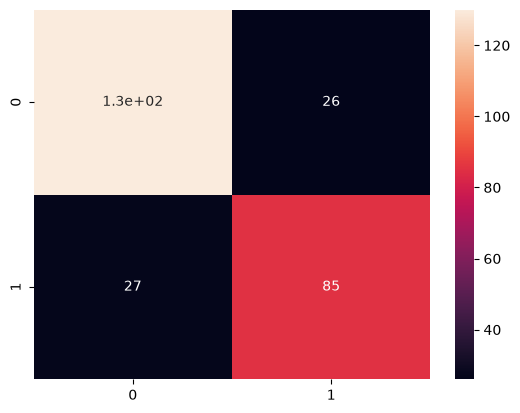

In [44]:
import seaborn as sns

sns.heatmap(cm, annot=True)



```
# Isto está formatado como código
```

## Curva ROC

Text(0.5, 1.0, 'Curva ROC')

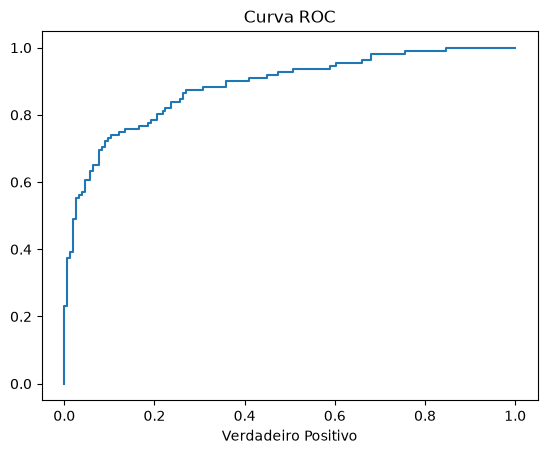

In [45]:
from sklearn.metrics import roc_curve
prob = classifier.predict_proba(x_test)
prob = prob[:,1]
fpr, tpr, threshold = roc_curve(y_test, prob)

plt.plot(fpr, tpr)
plt.xlabel('Falso Positivo')
plt.xlabel('Verdadeiro Positivo')
plt.title('Curva ROC')

## Precision e Recall

In [46]:
from sklearn.metrics import precision_score, recall_score, f1_score

print(precision_score(y_test, y_pred))
print(recall_score(y_test, y_pred))
print(f1_score(y_test, y_pred))

0.7657657657657657
0.7589285714285714
0.7623318385650224
